In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split, TensorDataset
from torchvision import datasets, transforms
import os
import random
import numpy as np

SEED = 0
torch.manual_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
g = torch.Generator()
g.manual_seed(0)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'  # or ':16:8'


################################
#     RESTART     RUNTIME      #
################################
from ssonn.model.utils import *
from ssonn.metrics.nonlinearity_metrics import *
from ssonn.metrics.edge_finder import *
from ssonn.metrics.train_metrics import *
from ssonn.train.train import *

In [2]:
class SimpleFCN(nn.Module):
    def __init__(self, input_size=28 * 28, hidden_size=16):
        super(SimpleFCN, self).__init__()
        self.fc0 = nn.Linear(input_size, 10)
        # self.fc1 = nn.Linear(hidden_size, 10)
        # self.act = nn.ReLU()

    def forward(self, x):
        x = self.fc0(x)
        return x

In [3]:
hyperparams = {
    "num_epochs": 128,
    "batch_size": 256,
    "edge_importance_metric": AbsGradientEdgeMetric(nn.CrossEntropyLoss()), # replace to default
    "edge_score_aggregation": "mean",
    "expansion_thresholds": {"fc0": 0.3},
    "pruning_thresholds": {"fc0": 1},
    "plateau_threshold": 0.01,
    # "min_epochs_between_expansions": 16,
    "min_epochs_between_expansions": 10_000,
    "plateau_window_size": 5,
    "learning_rate": 1e-3,
    "prune_after_epochs": 4,
    "task_type": "classification",
    "start_fully_connected": False,
    "max_new_edges_per_expansion": 500,
    "weight_decay": 1e-4,
    "diff_threshold": 0.01
}

In [4]:
# Dataset and Dataloader
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))
])

# Load dataset and split into train/validation sets
dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

train_dataset, val_dataset = random_split(dataset, [0.8, 0.2])

train_loader = DataLoader(train_dataset, batch_size=hyperparams['batch_size'], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=hyperparams['batch_size'], shuffle=False)

In [5]:
model = SimpleFCN()
sparse_model = convert_dense_to_sparse_network(model, layers=[model.fc0], device=device)

In [6]:
# import wandb
# wandb.login()

In [7]:
# wandb.finish()
# run = wandb.init(
#     project="self-expanding-nets",
#     name=f"name",
#     config=hyperparams
# )

In [8]:
# !sudo COMET_API_KEY="frGbe20bUNVBiHdnVG40YiMwA"
# !export COMET_WORKSPACE="vanya9090"
os.environ.get("COMET_API_KEY")

In [9]:
from comet_ml import start
from comet_ml.integration.pytorch import log_model
experiment = start(
    api_key="frGbe20bUNVBiHdnVG40YiMwA",
    workspace="vanya9090",
    project_name="mnist",
)
experiment.log_parameters(hyperparams)

experiment.set_name("trash")

COMET WARNING: To get all data logged automatically, import comet_ml before the following modules: sklearn, torch.
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/vanya9090/mnist/257593eca91d4e8e9add7f0bbf261f0e



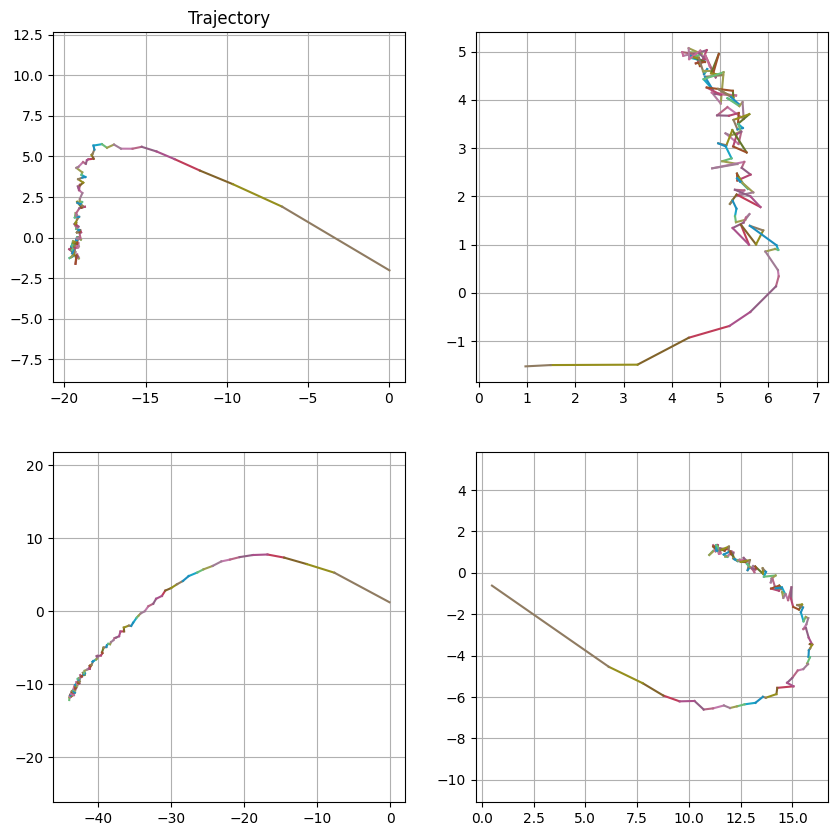

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(sparse_model.parameters(), lr=hyperparams['learning_rate'], weight_decay=hyperparams['weight_decay'])
train_sparse_recursive(sparse_model, train_loader, train_loader, val_loader, criterion,optimizer, hyperparams, device, experiment)

большой lr

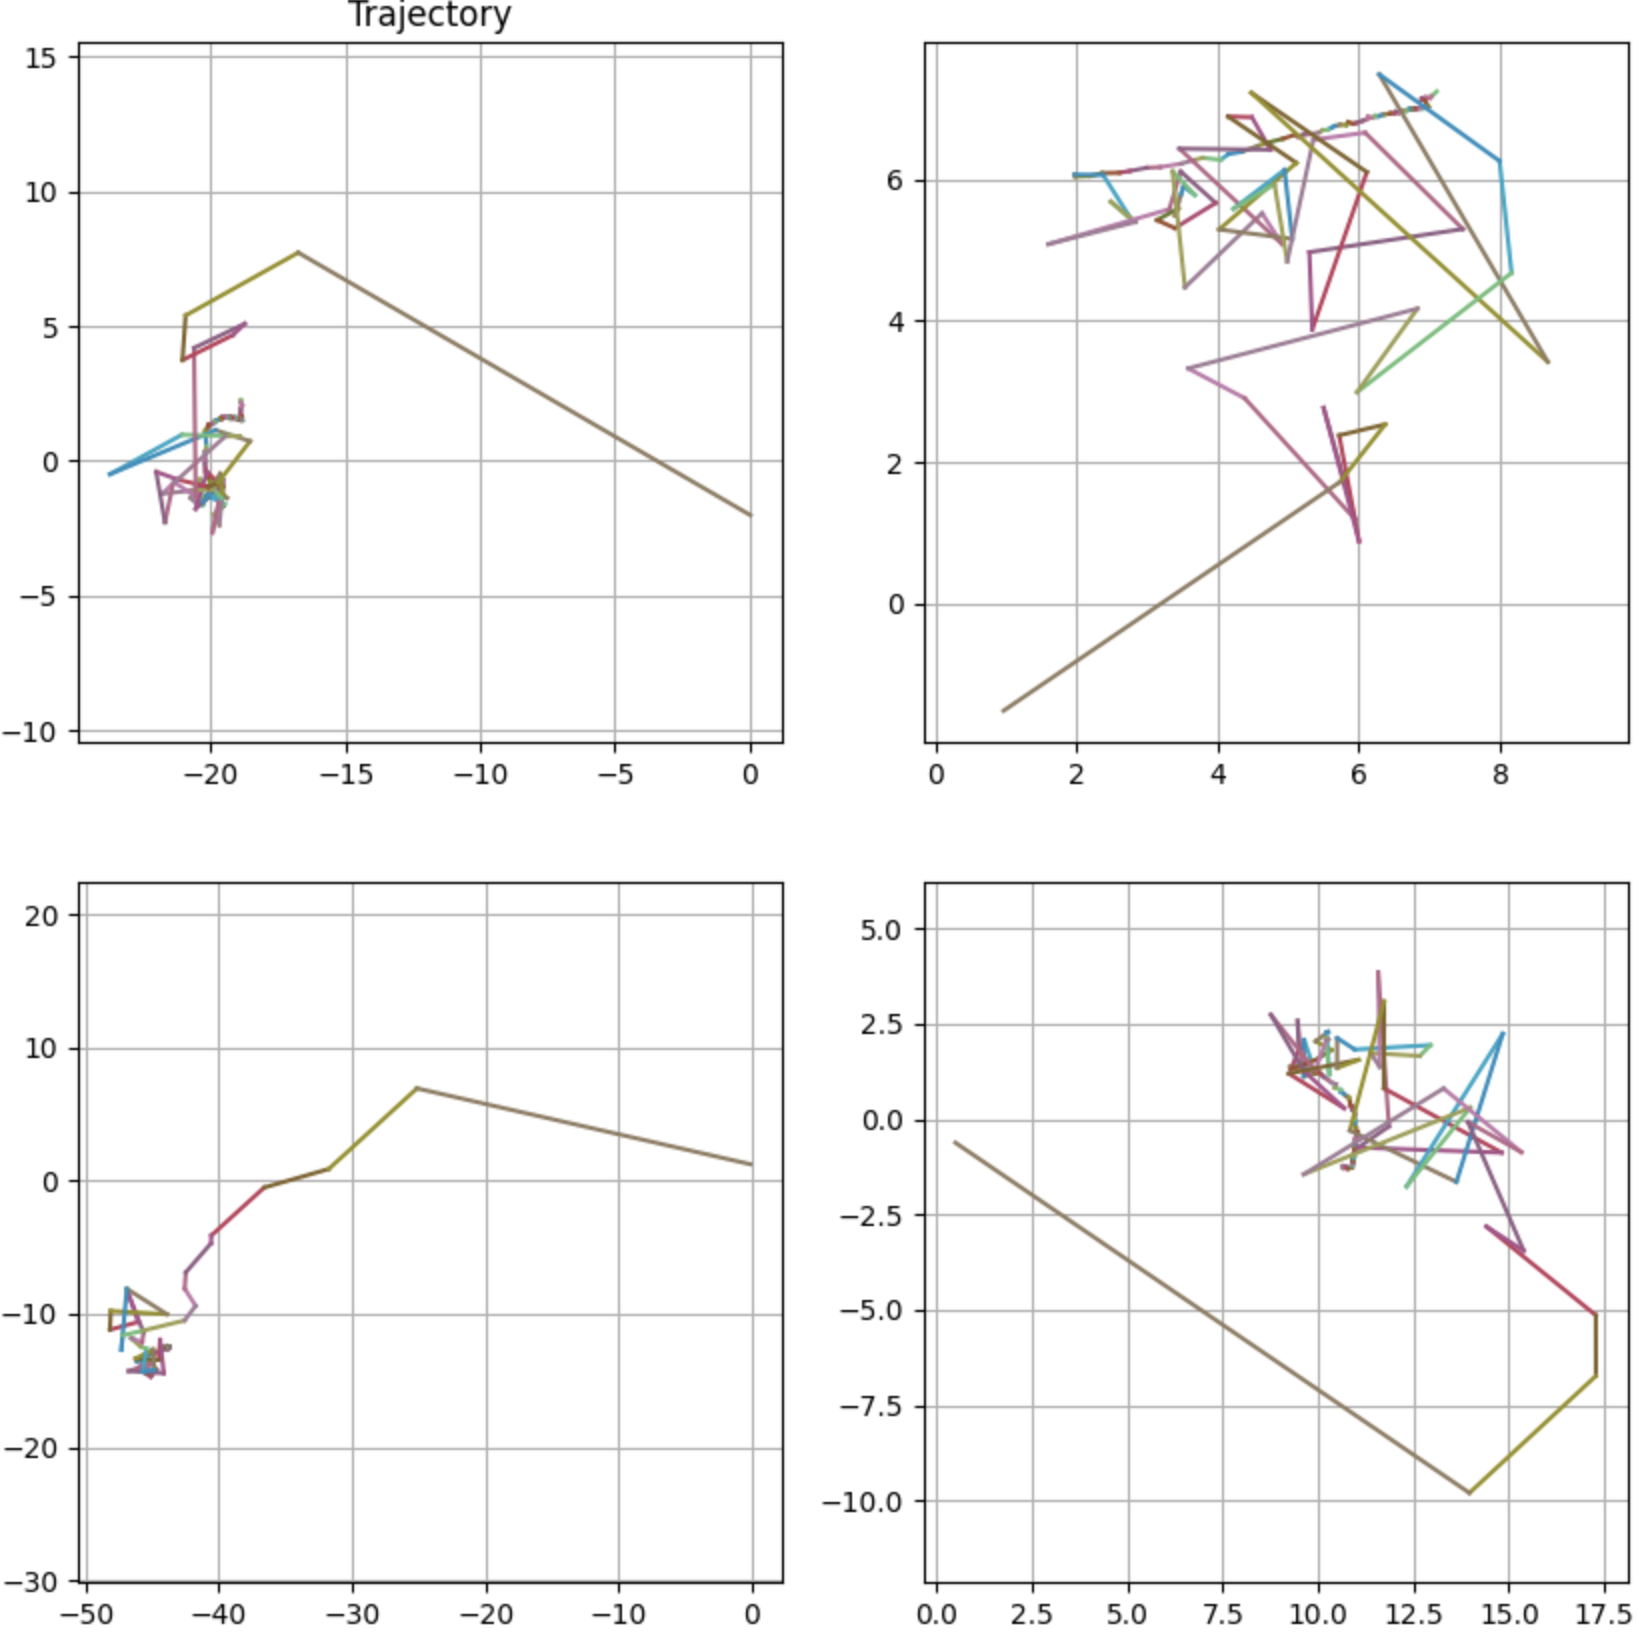

траектория с добавлением новых параметров в проектор

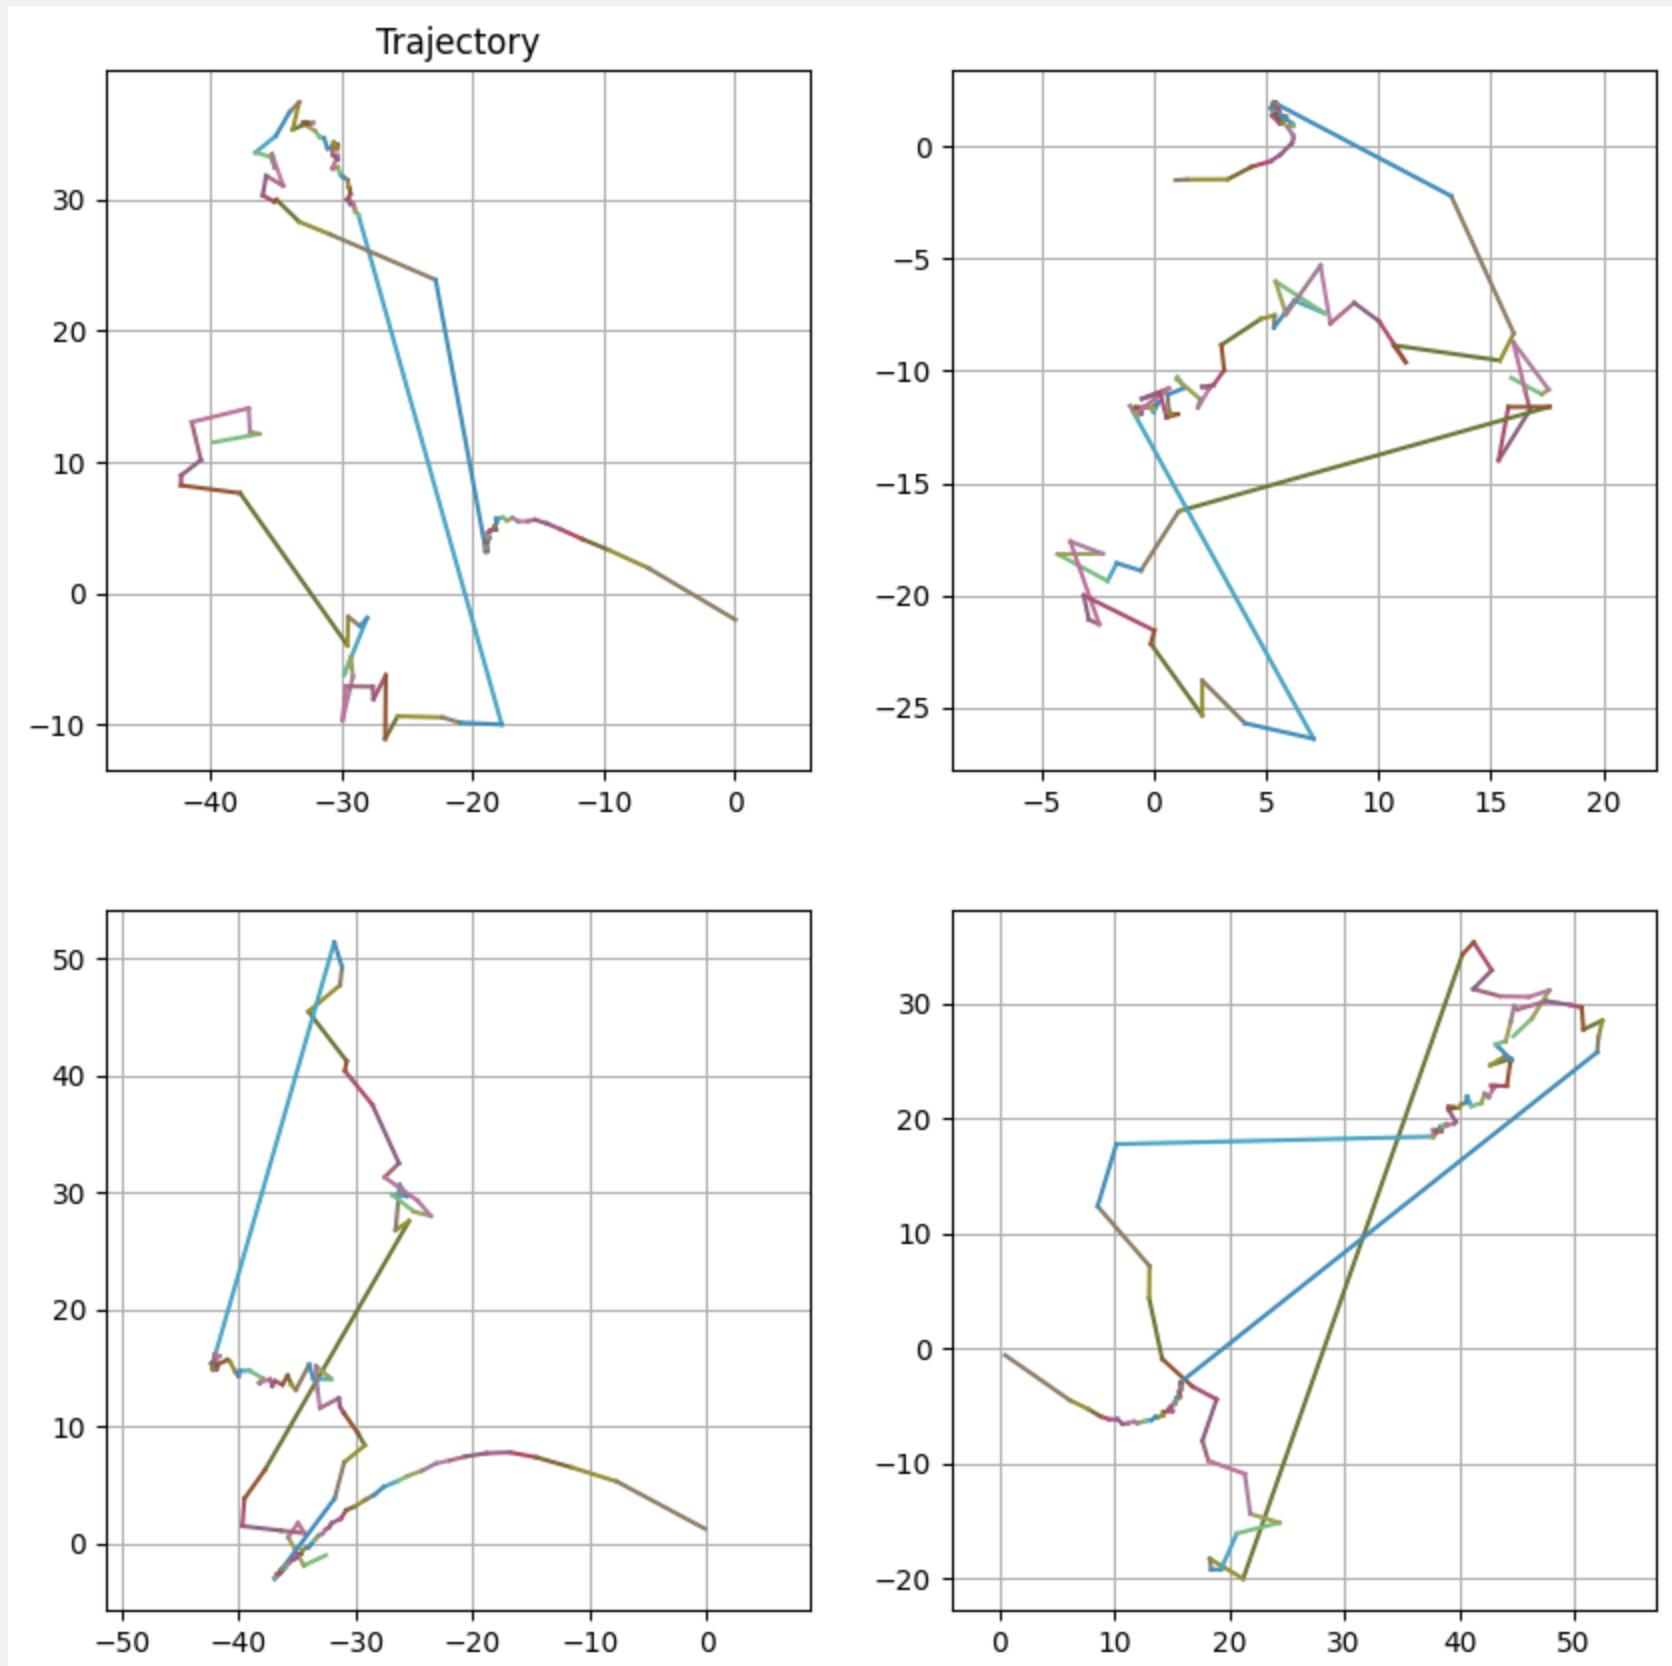

траектория обучения без добавления новых параметров в проектор

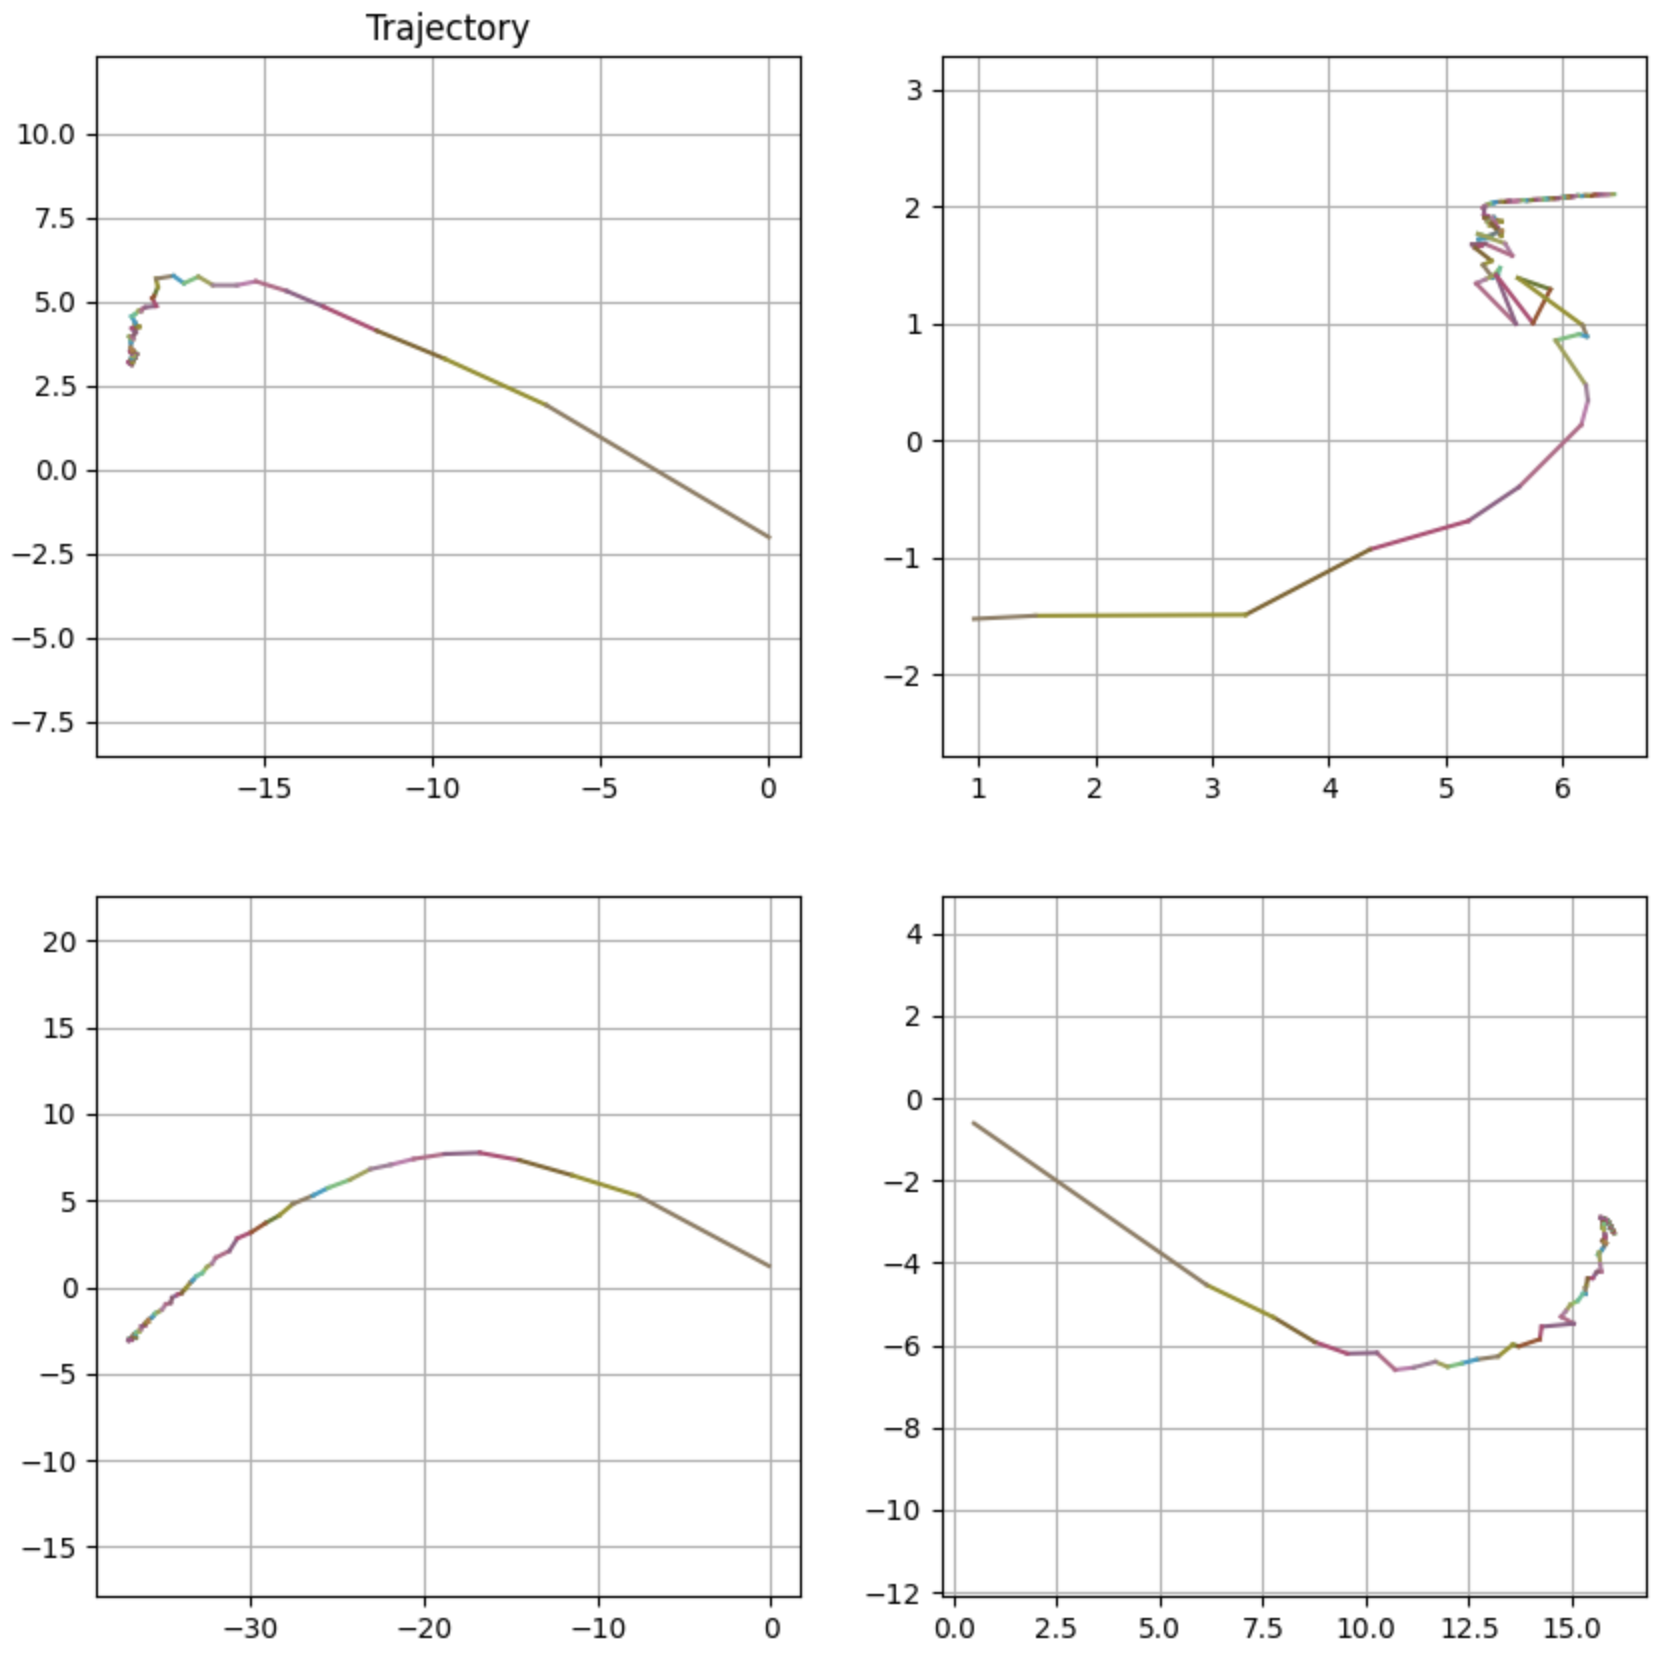

In [11]:
experiment.end()

COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : trash
COMET INFO:     url                   : https://www.comet.com/vanya9090/mnist/257593eca91d4e8e9add7f0bbf261f0e
COMET INFO:   Metrics [count] (min, max):
COMET INFO:     acc amount [128]               : (0.00011084183673469388, 0.00011800595238095239)
COMET INFO:     lr                             : 0.001
COMET INFO:     n_params over train_time [128] : (3180.1639223294924, 4468.708341651289)
COMET INFO:     params amount                  : 7840
COMET INFO:     params ratio                   : 0.9362244897959183
COMET INFO:     params to replace amount       : 500
COMET INFO:     train loss [128]               : (0.2386263228081008, 0.9322063074

In [12]:
torch.save(sparse_model, 'mnist.pt')